# The jump equation, v2: how the joint model behaves on data it generated itself

This notebook implements the model in *Jump Equation v2* and studies it entirely on simulated
data, where every parameter is known. The point is to see what the method can and cannot
recover, how much data it needs, and which modelling choices matter, *before* it meets a real
price series. No market data is used anywhere below.

The model is a pair of equations on the two pieces a trading day splits into: the overnight
jump $J_t$ and the cumulative intraday return curve $X_t(s)$, both in percent.

$$
\begin{aligned}
J_t &= \alpha + \rho J_{t-1} + \int_0^1 \beta(u)\, X_{t-1}(u)\,\mathrm{d}u + \eta_t, \\
X_t(s) &= \mu(s) - \gamma_t G(s) J_t + \int_0^1 \Psi(s,r)\, X_{t-1}(r)\,\mathrm{d}r
          + \varepsilon_t(s), \qquad
\varepsilon_t(s) = \int_0^s \sigma(v)\,\mathrm{d}W_t(v).
\end{aligned}
$$

Three identities on the log-price curve $P_t$ tie the pieces together: $P_t(s) = P_{t-1}(1) +
J_t + X_t(s)$, $X_t(s) = P_t(s) - P_t(0)$ and $J_t = P_t(0) - P_{t-1}(1)$.
`jump.joint_dgp` holds the model, its theory and its simulator, and `jump.joint_est` the
estimators. `tests/test_joint.py` checks both, the model against its own definitions before
the estimators against the model. `docs/jump-model-choices.md` explains, without the code, the
three modelling choices that sections 7 to 9 investigate.

**What it finds.**

- **The model is consistent, once it is read as one system** (sections 1 and 3). The
  identities hold to rounding on every simulated path. The stationary mean solves the notes'
  expectation equation together with the jump-mean equation it needs alongside. The solved
  moments match 100,000 simulated days. Stationarity is a joint condition, not two separate
  ones.
- **Every scalar comes back** (sections 5 and 6). $\alpha$, $\rho$, $\sigma_\eta$ and $\gamma$
  are unbiased at the parametric rate, with intervals that cover. A GLS estimator of $\gamma$
  that uses the Brownian structure of the curve noise has about a fifth less variance than the
  obvious projection.
- **$\beta$'s effect on the jump is recoverable; $\beta$ itself is ill-posed** (section 5), as
  functional regression theory says it must be.
- **"$\beta$ on the curve" can mean two models, and the data can tell them apart** (section 7).
  A step on the level says the jump responds to the whole day's move; a step on the returns
  says only the last stretch matters. Fitted to the other's data, each captures a small part
  of the signal even with infinite data. A regression on both names the right one from a year
  of data. Only the step on returns has an onset that can be located sharply.
- **The sign of $\Psi$ decides continuation against reversal** (section 8). The notes' kernel
  allows only continuation; a free sign costs nothing.
- **$G(s) = s$ is testable, with power from a year or two of data; $\operatorname{Var}\gamma_t$
  needs decades** (section 9).

The three figures asked for are in section 4: the curves laid end to end with each overnight
gap coloured by direction, the jump bar chart aligned underneath, and the histogram of the jumps.

## 1. Reading the notes

**What holds.** The three identities are consistent with each other and with the "consistent
original equation", $P_t(s) = P_{t-1}(1) + (1-\gamma_t s)J_t + \mu(s) + \int\Psi X_{t-1} +
\varepsilon_t(s)$, which is just the curve equation substituted into the first identity. The
edit that moves $(1 - s\gamma)$ off yesterday's close and onto the jump is right. Under the old
form, a fraction $\gamma$ of the *price level* was erased by every close: that is not a gap
filling, it is the price drifting to zero. The boundary conditions $\mu(0) = G(0) =
\Psi(0,\cdot) = \varepsilon_t(0) = 0$ are what $X_t(0) = 0$ needs, and
$\varepsilon_t(s) = \int_0^s \sigma(v)\,\mathrm{d}W_t(v)$ delivers the last of them almost
surely. Equation $(\ast)$ does hold as the conditional mean given yesterday.

**What needs correcting or adding**, roughly in the order it matters:

1. **"$\beta$ on the curve" can mean two different models.** As written, $\beta$ multiplies the
   curve's *level*. A coefficient that is zero before 0.85 on the level is not the same as one
   that is zero before 0.85 on the *returns*, and the difference decides both what the model
   says and whether its onset can be found. Section 7 compares the two in full.
2. **Stationarity is a joint condition, not two separate ones.** Substituting the jump into the
   curve equation writes the pair as a single autoregression on $(J_t, X_t)$, and the two
   equations are coupled. With $\Psi = 0$, the jump's effective persistence is
   $\rho - \gamma\langle\beta, G\rangle$, because yesterday's gap-fill is part of yesterday's
   curve and $\beta$ feeds it into tonight's jump. So $|\rho| < 1$ and $\|\Psi\| < 1$ do not
   guarantee a stationary pair; `tests/test_joint.py` builds one that explodes. With random
   $\gamma_t$ the condition is on the mean-square operator, as for any autoregression with random
   coefficients [[63]](../docs/references.md#ref-nicholls-quinn-1982).
3. **The expectation equation is half of a system.** $m(s) = \mu(s) - \bar\gamma G(s)\,
   \mathbb{E}J + \int\Psi(s,r)m(r)\,\mathrm{d}r$ is right, but $\mathbb{E}J$ is itself
   $(\alpha + \langle\beta, m\rangle)/(1-\rho)$, so the two have to be solved together. It also
   needs $\gamma_t$ independent of $J_t$, which the notes imply and should say.
4. **"These ways of writing $J_t$ agree exactly" holds only for the conditional mean, and only
   with $\alpha = \rho = 0$.** Under the old model with the new boundary conditions, $J_t =
   \int\beta X_{t-1}$ exactly. The jump has no noise at all, because its noise used to be
   $\varepsilon_t(0)$, which is now zero. So the new equation's $\eta_t$ is not optional, and the
   new model strictly generalises the old one.
5. **The kernel can only produce continuation.** $\Psi(s,r) = s\,e^{-(s-r)^2/c}$ is never
   negative, so a good day can only push tomorrow up. Section 8 explains what that means and
   simulates the alternative.
6. **$G(s) = s$ and $\gamma \in [0, 1]$ are hypotheses, not definitions.** $G$ says *when*
   during the day the gap is given back, and $G(s) = s$ says at a constant rate. Section 9
   explains this and tests it. $\gamma < 0$ (the gap extends rather than fills) should remain
   possible in estimation.
7. **A typo, and some notation.** $\varepsilon_t(s) = \int_0^s\sigma(v)\,\mathrm{d}W_t(v)$
   has no trailing $\mathrm{d}v$: it is a stochastic integral. $\alpha$ is used both for the old
   curve intercept $\alpha_t(s)$ and for the new scalar jump intercept. $X^{\mathrm{old}}$ is a
   *price* while $X$ is a return curve, so a different letter for the price would help, say
   $S_t(s)$. And $\rho$ is the Hilbert-Schmidt norm everywhere else in this repository.

**Nothing in the system needs a joint estimator.** $J_t$ is formed from the past and
$\eta_t$, and $X_t$ from the past, $J_t$ and $\varepsilon_t$; the two errors are independent.
The conditional density therefore factorises, $f(J_t, X_t \mid \text{past}) =
f(J_t\mid\text{past})\, f(X_t \mid J_t, \text{past})$. The jump is exogenous in the curve
equation, and fitting the two equations separately is full-information estimation. The curve
equation is a functional autoregression with an exogenous variable [[25]](../docs/references.md#ref-damon-guillas-2002).

In [1]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy import stats

from fts_research.core import style
from fts_research.jump import joint_dgp as jd
from fts_research.jump import joint_est as est
from fts_research.truncFLR import HH

style.use(plt)
UP, DOWN, THIRD = style.CATEGORICAL          # a jump's direction, or a second and third series
CLOCK = time.perf_counter()

## 2. Choosing the data-generating process

The notes fix $\Psi$, $\beta$, $\gamma$ and $G$, and leave the rest open. A simulation design
is an experiment, so each remaining value below is chosen for what it makes visible, kept to
round numbers, and given a reason. Units are percent log returns, so 1 means 1%.

| parameter | value | why |
|---|---|---|
| grid | 79 points | five-minute bars over a 6.5-hour session, plus the open |
| $\sigma^2(v)$ | U-shaped, ends 2.5× the middle, integrating to 1 | intraday volatility is highest at the open and the close [[1]](../docs/references.md#ref-andersen-bollerslev-1997); a session standard deviation of 1% |
| $\sigma_\eta$ | 0.5 | an overnight move about half the size of a day's, so the gap-fill is visible without swamping the curve |
| $\alpha$, $\mu(s)$ | $0.05$, $-0.02\,s$ | small positive drift overnight and small negative drift intraday, the sign pattern of [[23]](../docs/references.md#ref-cliff-cooper-gulen-2008) |
| $\rho$ | 0.1 | small, as jumps barely persist, but not zero, so it is something to recover |
| $\Psi$ | $s\,e^{-(s-r)^2/0.1}$ | the notes' kernel; $c = 0.1$ lets each part of the day depend on roughly the same part of yesterday |
| $\beta$, $\gamma$, $G$ | $\mathbb{1}\{u \ge 0.85\}$, 0.3, $s$ | the notes' values |

Nothing here is fitted to data. Where the design is varied below, by the sign of $\Psi$, the
shape of $G$, the spread of $\gamma_t$, the shape of $\beta$ or the size of its effect, one
thing changes at a time.

stationary mean:  E J = 0.0483,  E X(1) = -0.0458
standard deviations: jump 0.5214, session 1.0320
population R^2 of the jump equation 0.0805; of the jump's lag alone 0.0063
lag-1 autocorrelation: jump +0.0794, session return X(1) +0.1842


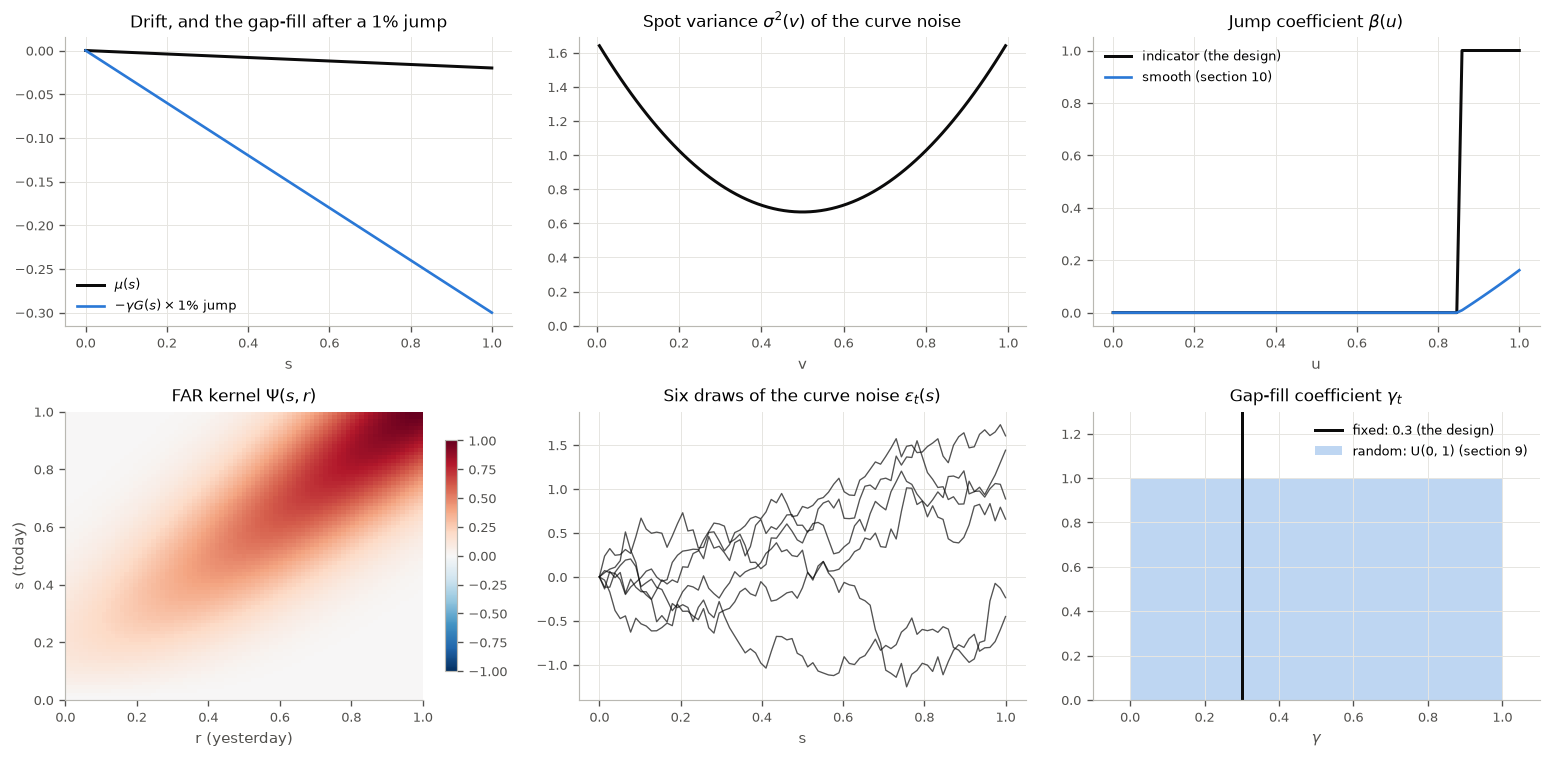

In [2]:
model = jd.notes_design()
grid, w = model.grid, model.w
mom = jd.moments(model)
check = jd.stationarity(model)
floor = jd.population_fit(model, None, mom)["r2"]
mids = 0.5 * (grid[1:] + grid[:-1])

print(f"stationary mean:  E J = {mom['mean_J']:.4f},  E X(1) = {mom['mean_X'][-1]:.4f}")
print(f"standard deviations: jump {np.sqrt(mom['var_J']):.4f}, "
      f"session {np.sqrt(mom['cov_X'][-1, -1]):.4f}")
print(f"population R^2 of the jump equation {mom['r2_jump']:.4f}; "
      f"of the jump's lag alone {floor:.4f}")
print(f"lag-1 autocorrelation: jump {mom['acf1_J']:+.4f}, session return X(1) "
      f"{mom['lag1'][-1, -1] / mom['cov_X'][-1, -1]:+.4f}")

fig, ax = plt.subplots(2, 3, figsize=(13, 6.4))
a = ax[0, 0]
a.plot(grid, model.mu, color=style.INK, lw=1.8, label=r"$\mu(s)$")
a.plot(grid, -model.gamma_mean * model.G * 1.0, color=UP, lw=1.6,
       label=r"$-\gamma G(s)\times 1\%$ jump")
a.set_title("Drift, and the gap-fill after a 1% jump")
a.set_xlabel("s")
a.legend()
a = ax[0, 1]
a.plot(mids, model.cell_var / np.diff(grid), color=style.INK, lw=1.8)
a.set_ylim(0, None)
a.set_title(r"Spot variance $\sigma^2(v)$ of the curve noise")
a.set_xlabel("v")
a = ax[0, 2]
a.plot(grid, model.beta, color=style.INK, lw=1.8, label="indicator (the design)")
a.plot(grid, jd.notes_beta(grid, "smooth"), color=UP, lw=1.6, label="smooth (section 10)")
a.set_title(r"Jump coefficient $\beta(u)$")
a.set_xlabel("u")
a.legend()
a = ax[1, 0]
image = a.imshow(model.kernel, origin="lower", extent=[0, 1, 0, 1], cmap="RdBu_r",
                 vmin=-1, vmax=1, aspect="auto")
a.grid(False)
a.set_title(r"FAR kernel $\Psi(s, r)$")
a.set_xlabel("r (yesterday)")
a.set_ylabel("s (today)")
fig.colorbar(image, ax=a, shrink=0.8)
a = ax[1, 1]
for path in jd.simulate(model, 6, rng=5)["eps"]:
    a.plot(grid, path, color=style.INK, lw=0.8, alpha=0.7)
a.set_title(r"Six draws of the curve noise $\varepsilon_t(s)$")
a.set_xlabel("s")
a = ax[1, 2]
a.axvline(0.3, color=style.INK, lw=1.8, label="fixed: 0.3 (the design)")
a.fill_between([0, 1], 0, 1, color=UP, alpha=0.3, lw=0, label="random: U(0, 1) (section 9)")
a.set_xlim(-0.1, 1.1)
a.set_ylim(0, 1.3)
a.set_title(r"Gap-fill coefficient $\gamma_t$")
a.set_xlabel(r"$\gamma$")
a.legend()
plt.tight_layout()
plt.show()

The population $R^2$ is small by design. Yesterday's curve explains a few percent of tonight's
jump, which is the order of magnitude a predictable component of a daily return can have
without being traded away. It also means that sample size, more than the estimator, decides
most of what follows. A ten-year sample is about 2520 days.

## 3. The model is consistent, numerically

Before simulating from the model, check it against its own algebra. The four checks below
are also tests in `tests/test_joint.py`:

- stationarity, both as the joint condition and as the decoupled one the notes would have
  checked;
- the two mean equations;
- the identities, on a simulated path;
- the solved moments, against a long simulation.

In [3]:
print(f"spectral radius of E A_t (joint):       {check['radius']:.4f}")
print(f"mean-square radius:                     {check['ms_radius']:.4f}")
print(f"largest of |rho| and radius(Psi) alone: {check['decoupled']:.4f}")

EJ, m = mom["mean_J"], mom["mean_X"]
curve_eq = model.mu - model.gamma_mean * model.G * EJ + model.Psi_op @ m - m
jump_eq = model.alpha + model.rho * EJ + np.sum(model.beta * w * m) - EJ
print(f"\nthe notes' mean-curve equation, largest residual: {np.max(np.abs(curve_eq)):.1e}")
print(f"the jump-mean equation it needs alongside:        {abs(jump_eq):.1e}")

long = jd.simulate(model, 100_000, rng=0)
P = jd.price_curves(long["J"], long["X"])
print(f"\nmax |X_t(0)|                      {np.max(np.abs(long['X'][:, 0])):.1e}")
print(f"max |P_t(0) - P_t-1(1) - J_t|     "
      f"{np.max(np.abs(P[1:, 0] - P[:-1, -1] - long['J'][1:])):.1e}")
print(f"max |P_t(s) - P_t(0) - X_t(s)|    {np.max(np.abs(P - P[:, [0]] - long['X'])):.1e}")

J_l, X_l = long["J"], long["X"]
table = pd.DataFrame({
    "theory": [mom["mean_J"], mom["var_J"], mom["acf1_J"], mom["mean_X"][-1],
               mom["cov_X"][-1, -1], mom["cov_X"][39, 39]],
    "100,000 simulated days": [J_l.mean(), J_l.var(), np.corrcoef(J_l[:-1], J_l[1:])[0, 1],
                               X_l[:, -1].mean(), X_l[:, -1].var(), X_l[:, 39].var()]},
    index=["E J", "Var J", "acf1 J", "E X(1)", "Var X(1)", "Var X(1/2)"])
print()
print(table.round(4).to_string())

spectral radius of E A_t (joint):       0.2171
mean-square radius:                     0.0471
largest of |rho| and radius(Psi) alone: 0.2960

the notes' mean-curve equation, largest residual: 2.8e-17
the jump-mean equation it needs alongside:        6.9e-18



max |X_t(0)|                      0.0e+00
max |P_t(0) - P_t-1(1) - J_t|     8.5e-14
max |P_t(s) - P_t(0) - X_t(s)|    2.8e-14

            theory  100,000 simulated days
E J         0.0483                  0.0475
Var J       0.2719                  0.2726
acf1 J      0.0794                  0.0787
E X(1)     -0.0458                 -0.0483
Var X(1)    1.0650                  1.0587
Var X(1/2)  0.5322                  0.5320


## 4. What the model produces

Ten years of trading days from the design. The first figure lays the curves end to end, as a
price chart would. Each session is drawn as its log-price curve, and the overnight gap to the
next session as a coloured segment: blue where the market opened up, orange where it opened
down. The bars underneath are the same jumps on the same days, centred under their gaps, so
magnitude and direction can be read together and against the path.

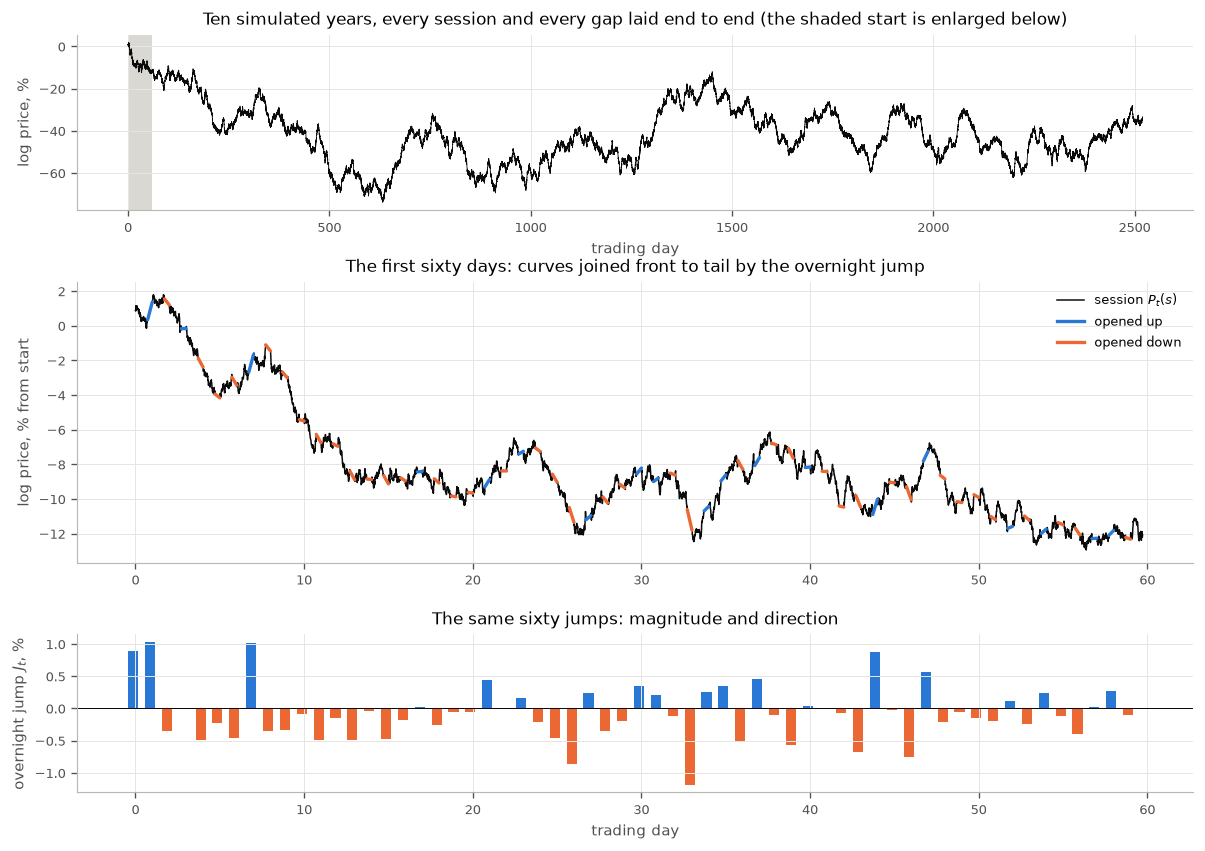

2520 days; 53.2% of jumps up; largest +1.84%, smallest -1.72%


In [4]:
sim = jd.simulate(model, 2520, rng=1)
J, X = sim["J"], sim["X"]
P = jd.price_curves(J, X)

TRADING = 0.72          # share of each day's slot on the x axis drawn as the session


def draw_path(ax, J, X, first, days, grid):
    # Sessions as curves, overnight gaps as coloured connectors, end to end.
    P = jd.price_curves(J, X)
    for t in range(first, first + days):
        x0 = t - first
        ax.plot(x0 + TRADING * grid, P[t], color=style.INK, lw=0.9)
        if t > first:
            colour = UP if J[t] >= 0 else DOWN
            ax.plot([x0 - 1 + TRADING, x0], [P[t - 1, -1], P[t, 0]], color=colour, lw=2.0,
                    solid_capstyle="round")
    ax.set_ylabel("log price, % from start")


def draw_bars(ax, J, first, days):
    # One bar per jump, centred on the overnight gap it is, coloured by direction.
    x = np.arange(days) - 0.5 * (1 - TRADING)
    jumps = J[first:first + days]
    ax.bar(x, jumps, width=0.6, color=np.where(jumps >= 0, UP, DOWN), lw=0)
    ax.axhline(0, color=style.INK, lw=0.6)
    ax.set_ylabel("overnight jump $J_t$, %")
    ax.set_xlabel("trading day")


legend = [Line2D([], [], color=style.INK, lw=0.9, label="session $P_t(s)$"),
          Line2D([], [], color=UP, lw=2, label="opened up"),
          Line2D([], [], color=DOWN, lw=2, label="opened down")]

fig = plt.figure(figsize=(12, 8.2))
grid_spec = fig.add_gridspec(3, 1, height_ratios=[1.0, 1.6, 0.9], hspace=0.35)
ax0 = fig.add_subplot(grid_spec[0])
ax0.plot(np.arange(P.size) / grid.size, P.ravel(), color=style.INK, lw=0.5)
ax0.axvspan(0, 60, color=style.BAND, lw=0)
ax0.set_title("Ten simulated years, every session and every gap laid end to end "
              "(the shaded start is enlarged below)")
ax0.set_xlabel("trading day")
ax0.set_ylabel("log price, %")
ax1 = fig.add_subplot(grid_spec[1])
draw_path(ax1, J, X, 0, 60, grid)
ax1.set_title("The first sixty days: curves joined front to tail by the overnight jump")
ax1.legend(handles=legend, loc="best")
ax2 = fig.add_subplot(grid_spec[2], sharex=ax1)
draw_bars(ax2, J, 0, 60)
ax2.set_title("The same sixty jumps: magnitude and direction")
plt.show()
style.save_figure(fig, "jump_v2_contiguous")
print(f"{J.size} days; {np.mean(J > 0):.1%} of jumps up; "
      f"largest {J.max():+.2f}%, smallest {J.min():+.2f}%")

The histogram is the distribution of $J_t$ the recursion produces. With Gaussian $\eta_t$ and
Gaussian curve noise the whole system is linear and Gaussian, so the stationary law of $J_t$
is *exactly* normal with the solved mean and variance. The left panel overlays that density
rather than one fitted to the sample.

Real overnight returns are well known to be heavier tailed than that. The right panel swaps
$\eta_t$ for a Student $t$ on five degrees of freedom with the same variance (`eta_df=5`). It
is drawn on a log scale, where the difference lives in the tails. Nothing in the estimators
assumes normality, and section 6 reruns the main recovery check with these innovations.

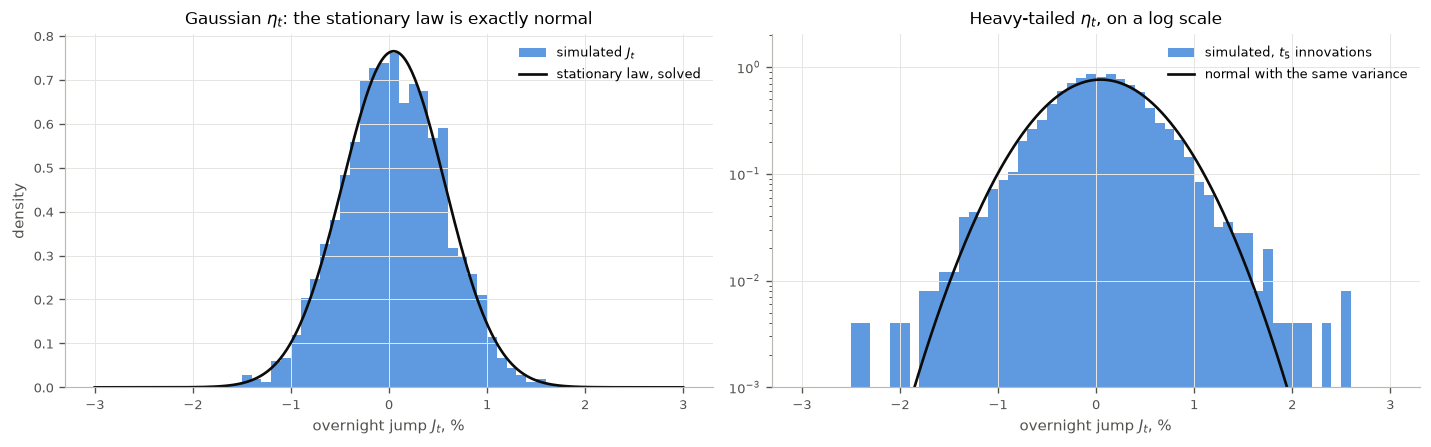

Gaussian innovations  sd 0.522  skew -0.01  excess kurtosis -0.05  Jarque-Bera p 0.842
t5 innovations        sd 0.540  skew -0.28  excess kurtosis  4.59  Jarque-Bera p 0


In [5]:
model_t = jd.notes_design(eta_df=5.0)
sim_t = jd.simulate(model_t, 2520, rng=1)
mom_t = jd.moments(model_t)
bins = np.linspace(-3, 3, 61)
x = np.linspace(-3, 3, 400)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].hist(J, bins=bins, density=True, color=UP, alpha=0.75, lw=0, label="simulated $J_t$")
ax[0].plot(x, stats.norm.pdf(x, mom["mean_J"], np.sqrt(mom["var_J"])), color=style.INK,
           lw=1.6, label="stationary law, solved")
ax[0].set_title("Gaussian $\\eta_t$: the stationary law is exactly normal")
ax[0].set_xlabel("overnight jump $J_t$, %")
ax[0].set_ylabel("density")
ax[0].legend()

ax[1].hist(sim_t["J"], bins=bins, density=True, color=UP, alpha=0.75, lw=0,
           label="simulated, $t_5$ innovations")
ax[1].plot(x, stats.norm.pdf(x, mom_t["mean_J"], np.sqrt(mom_t["var_J"])), color=style.INK,
           lw=1.6, label="normal with the same variance")
ax[1].set_yscale("log")
ax[1].set_ylim(1e-3, None)
ax[1].set_title("Heavy-tailed $\\eta_t$, on a log scale")
ax[1].set_xlabel("overnight jump $J_t$, %")
ax[1].legend()
plt.tight_layout()
plt.show()
style.save_figure(fig, "jump_v2_histogram")

for label, series in (("Gaussian innovations", J), ("t5 innovations", sim_t["J"])):
    print(f"{label:<21} sd {series.std():.3f}  skew {stats.skew(series):+.2f}  "
          f"excess kurtosis {stats.kurtosis(series):5.2f}  "
          f"Jarque-Bera p {stats.jarque_bera(series).pvalue:.3g}")

## 5. Estimating it once

One ten-year sample, both equations, every parameter set against its truth.

- **The jump equation** is `jump_eq`'s estimator, with the principal component scores of
  $X_{t-1}$ standing in for the curve.
- **The curve equation** is fitted at every grid point on $(1, J_t, \xi_{t-1})$, where
  $\xi_{t-1}$ are the scores of yesterday's curve. This is principal component regression on
  the predictor side [[83]](../docs/references.md#ref-yao-muller-wang-2005), with the jump alongside.

The slope on the jump, $\hat b(s)$, estimates the gap-fill profile $-\gamma G(s)$, and
$\gamma$ is read off it in two ways:

- **projection**: $\hat\gamma = -\langle\hat b, G\rangle/\|G\|^2$;
- **GLS**: generalised least squares on the increments of $\hat b$, each weighted by the
  estimated noise variance over its cell. The increments of $\varepsilon_t$ are independent,
  so this is the Gaussian maximum likelihood estimator of $\gamma$ given the rest.

$\beta$ and $\Psi$ can only be estimated within the span of the retained components. So the
figure draws, beside the truth, the best $\beta$ that span can express: its projection onto
the leading *population* eigenfunctions, taken from the solved covariance. The gap between that
and the truth is the cost of truncation, not of estimation.

In [6]:
jump_fit = {p: est.fit_jump_equation(J, X, grid, n_components=p) for p in (2, 4, 8)}
curve_fit = est.fit_curve_equation(J, X, grid, n_components=4)

# the population eigenfunctions, from the solved covariance, in the L2(w) metric
sw = np.sqrt(w)
evals, evecs = np.linalg.eigh(sw[:, None] * mom["cov_X"] * sw[None, :])
phi_pop = (evecs[:, ::-1] / sw[:, None]).T


def best_in_span(beta, p):
    # The L2 projection of beta onto the first p population eigenfunctions.
    basis = phi_pop[:p]
    return (basis * w) @ beta @ basis


fit4 = jump_fit[4]["fit"]
print(f"           truth    estimate   (se)")
print(f"alpha    {model.alpha:8.4f}  {jump_fit[4]['alpha']:9.4f}")
print(f"rho      {model.rho:8.4f}  {jump_fit[4]['rho']:9.4f}  ({fit4.se_ols[1]:.4f})")
print(f"sigma_eta{model.sigma_eta:8.4f}  {jump_fit[4]['sigma_eta']:9.4f}")
print(f"gamma    {model.gamma_mean:8.4f}  {curve_fit['gamma_ols']:9.4f}  "
      f"({curve_fit['se_ols']:.4f})  projection")
print(f"gamma    {model.gamma_mean:8.4f}  {curve_fit['gamma_gls']:9.4f}  "
      f"({curve_fit['se_gls']:.4f})  GLS")
chi2, df, p = fit4.wald("d", hac=False)
print(f"\njoint test that beta = 0: chi2 = {chi2:.2f} on {df} df, p = {p:.2g}")

           truth    estimate   (se)
alpha      0.0500     0.0490
rho        0.1000     0.1096  (0.0192)
sigma_eta  0.5000     0.5013
gamma      0.3000     0.3200  (0.0431)  projection
gamma      0.3000     0.3212  (0.0385)  GLS

joint test that beta = 0: chi2 = 196.29 on 4 df, p = 2.4e-41


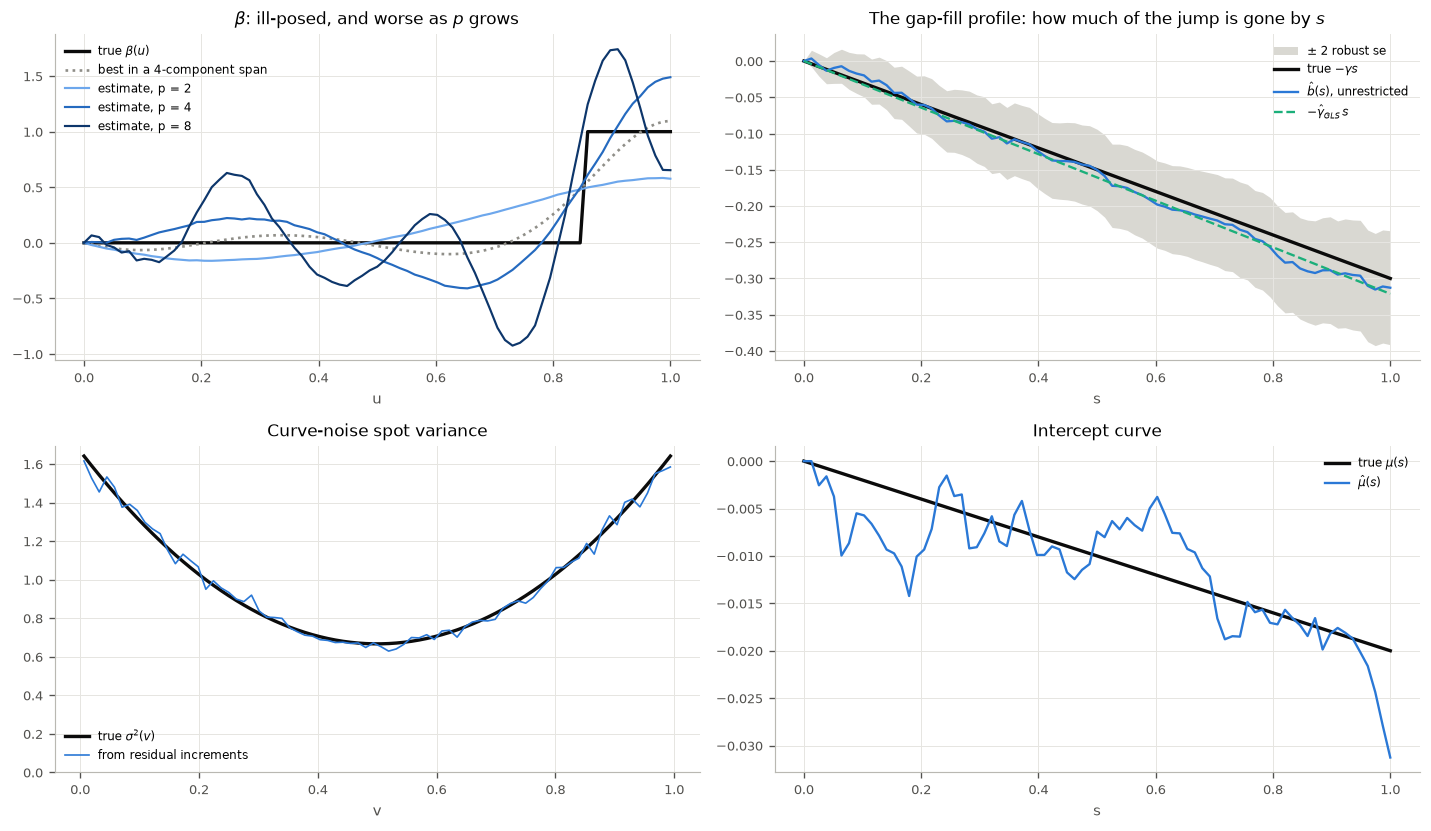

p = 2: L2 error of beta_hat 0.253 (truncation floor 0.252); correlation of fitted with true signal 0.984
p = 4: L2 error of beta_hat 0.239 (truncation floor 0.138); correlation of fitted with true signal 0.984
p = 8: L2 error of beta_hat 0.412 (truncation floor 0.111); correlation of fitted with true signal 0.978


In [7]:
fig, ax = plt.subplots(2, 2, figsize=(12, 7))
a = ax[0, 0]
a.plot(grid, model.beta, color=style.INK, lw=2, label=r"true $\beta(u)$")
a.plot(grid, best_in_span(model.beta, 4), color=style.CONTROL, lw=1.6, ls=":",
       label="best in a 4-component span")
for p, colour in zip((2, 4, 8), style.ordinal(3, lightest=4)):
    a.plot(grid, jump_fit[p]["beta_hat"], color=colour, lw=1.3, label=f"estimate, p = {p}")
a.set_title(r"$\beta$: ill-posed, and worse as $p$ grows")
a.set_xlabel("u")
a.legend(fontsize=7)

a = ax[0, 1]
band = 2 * np.sqrt(np.clip(np.diag(curve_fit["cov_b"]), 0, None))
a.fill_between(grid, curve_fit["b_hat"] - band, curve_fit["b_hat"] + band, color=style.BAND,
               lw=0, label="$\\pm$ 2 robust se")
a.plot(grid, -model.gamma_mean * model.G, color=style.INK, lw=2, label=r"true $-\gamma s$")
a.plot(grid, curve_fit["b_hat"], color=UP, lw=1.4, label=r"$\hat b(s)$, unrestricted")
a.plot(grid, -curve_fit["gamma_gls"] * model.G, color=THIRD, lw=1.4, ls="--",
       label=r"$-\hat\gamma_{GLS}\, s$")
a.set_title("The gap-fill profile: how much of the jump is gone by $s$")
a.set_xlabel("s")
a.legend(fontsize=7)

a = ax[1, 0]
a.plot(mids, model.cell_var / np.diff(grid), color=style.INK, lw=2,
       label=r"true $\sigma^2(v)$")
a.plot(mids, curve_fit["sigma2_hat"], color=UP, lw=1.0, label="from residual increments")
a.set_title("Curve-noise spot variance")
a.set_xlabel("v")
a.set_ylim(0, None)
a.legend(fontsize=7)

a = ax[1, 1]
a.plot(grid, model.mu, color=style.INK, lw=2, label=r"true $\mu(s)$")
a.plot(grid, curve_fit["mu_hat"], color=UP, lw=1.4, label=r"$\hat\mu(s)$")
a.set_title("Intercept curve")
a.set_xlabel("s")
a.legend(fontsize=7)
plt.tight_layout()
plt.show()

err = {p: np.sqrt(np.sum(w * (jump_fit[p]["beta_hat"] - model.beta) ** 2)) for p in (2, 4, 8)}
span = {p: np.sqrt(np.sum(w * (best_in_span(model.beta, p) - model.beta) ** 2))
        for p in (2, 4, 8)}
signal = X @ (model.beta * w)
for p in (2, 4, 8):
    fitted = X @ (jump_fit[p]["beta_hat"] * w)
    print(f"p = {p}: L2 error of beta_hat {err[p]:.3f} (truncation floor {span[p]:.3f}); "
          f"correlation of fitted with true signal {np.corrcoef(signal, fitted)[0, 1]:.3f}")

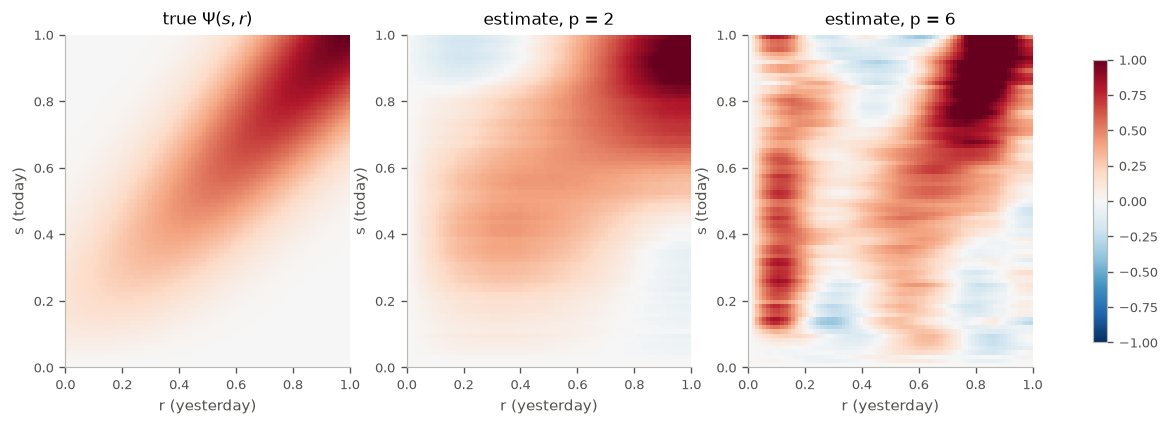

p = 2: Hilbert-Schmidt error of Psi_hat 0.0883
p = 3: Hilbert-Schmidt error of Psi_hat 0.1074
p = 4: Hilbert-Schmidt error of Psi_hat 0.1821
p = 6: Hilbert-Schmidt error of Psi_hat 0.2261
p = 8: Hilbert-Schmidt error of Psi_hat 0.6420


In [8]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
kernels = [("true $\\Psi(s, r)$", model.kernel)]
for p in (2, 6):
    kernels.append((f"estimate, p = {p}", est.fit_curve_equation(J, X, grid, p)["kernel"]))
for a, (title, K) in zip(ax, kernels):
    image = a.imshow(K, origin="lower", extent=[0, 1, 0, 1], cmap="RdBu_r", vmin=-1, vmax=1,
                     aspect="auto")
    a.set_title(title)
    a.set_xlabel("r (yesterday)")
    a.set_ylabel("s (today)")
    a.grid(False)
fig.colorbar(image, ax=ax, shrink=0.85)
plt.show()
for p in (2, 3, 4, 6, 8):
    K = est.fit_curve_equation(J, X, grid, p)["kernel"]
    print(f"p = {p}: Hilbert-Schmidt error of Psi_hat "
          f"{est.hs_distance(K, model.kernel, grid):.4f}")

Every scalar comes back, and the two functions behave exactly as functional regression theory
says they should [[19]](../docs/references.md#ref-cai-hall-2006)[[36]](../docs/references.md#ref-hall-horowitz-2007).

- **$\beta$'s effect on the jump is estimated well even where $\beta$ itself is not.** The
  fitted and true signals correlate closely at every $p$, while the reconstructed $\beta$
  oscillates around the step. A discontinuous $\beta$ cannot be built from a few smooth
  eigenfunctions, and each component added buys back some shape at a cost in variance that
  grows faster.
- **$\Psi$ behaves the same way**: its error is smallest with few components.
- **The gap-fill profile $\hat b(s)$ is different.** It is a slope on a scalar, not a
  functional coefficient, so it is estimated pointwise at the parametric rate, and its
  projection onto $G$ pins $\gamma$ down tightly.

## 6. Recoverability: a Monte Carlo

One sample says nothing about bias, or about whether the standard errors can be trusted. Two
hundred replications at each of three sample sizes, from one year of data to sixteen, give
both. Each replication records every estimate, its standard error, the gap-fill shape test of
section 9, and the joint test that $\beta \equiv 0$.

In [9]:
def replicate(design, n, reps, seed0, p=4):
    rows = []
    for r in range(reps):
        s = jd.simulate(design, n, rng=seed0 + r)
        jf = est.fit_jump_equation(s["J"], s["X"], design.grid, p)
        cf = est.fit_curve_equation(s["J"], s["X"], design.grid, p)
        rows.append({"n": n, "alpha": jf["alpha"], "rho": jf["rho"],
                     "se_rho": jf["fit"].se_ols[1], "sigma_eta": jf["sigma_eta"],
                     "gamma_ols": cf["gamma_ols"], "se_ols": cf["se_ols"],
                     "gamma_gls": cf["gamma_gls"], "se_gls": cf["se_gls"],
                     "p_shape": est.shape_test(cf)["p_value"],
                     "p_beta": jf["fit"].wald("d", hac=False)[2]})
    return rows


sizes = (252, 1008, 4032)
mc = pd.DataFrame([row for n in sizes for row in replicate(model, n, 200, 10_000 * n)])
mc_t = pd.DataFrame(replicate(model_t, 1008, 200, 7))


def summarise(frame, truth):
    out = {}
    for n, g in frame.groupby("n"):
        out[n] = {
            "rho: bias": g["rho"].mean() - truth.rho, "rho: sd": g["rho"].std(),
            "rho: 95% coverage": np.mean(np.abs(g["rho"] - truth.rho) < 1.96 * g["se_rho"]),
            "alpha: bias": g["alpha"].mean() - truth.alpha,
            "sigma_eta: bias": g["sigma_eta"].mean() - truth.sigma_eta,
            "gamma proj.: bias": g["gamma_ols"].mean() - truth.gamma_mean,
            "gamma proj.: sd": g["gamma_ols"].std(),
            "gamma proj.: coverage": np.mean(np.abs(g["gamma_ols"] - truth.gamma_mean)
                                             < 1.96 * g["se_ols"]),
            "gamma GLS: bias": g["gamma_gls"].mean() - truth.gamma_mean,
            "gamma GLS: sd": g["gamma_gls"].std(),
            "gamma GLS: coverage": np.mean(np.abs(g["gamma_gls"] - truth.gamma_mean)
                                           < 1.96 * g["se_gls"]),
            "shape test: rejects at 5%": np.mean(g["p_shape"] < 0.05),
            "beta = 0: rejects at 5%": np.mean(g["p_beta"] < 0.05)}
    return pd.DataFrame(out)


summary = summarise(mc, model)
print("200 replications per column; days per sample across the top")
print(summary.round(4).to_string())
print("\nwith t5 jump innovations, n = 1008:")
print(summarise(mc_t, model_t).round(4).to_string())
var_ratio = (summary.loc["gamma GLS: sd"] / summary.loc["gamma proj.: sd"]) ** 2
print(f"\nvariance of GLS gamma / projection gamma: {np.round(var_ratio.to_numpy(), 3)}")

200 replications per column; days per sample across the top
                             252     1008    4032
rho: bias                 -0.0054 -0.0060 -0.0018
rho: sd                    0.0650  0.0292  0.0159
rho: 95% coverage          0.9500  0.9600  0.9650
alpha: bias                0.0015  0.0010  0.0012
sigma_eta: bias           -0.0014  0.0003 -0.0001
gamma proj.: bias         -0.0096 -0.0014  0.0008
gamma proj.: sd            0.1466  0.0670  0.0356
gamma proj.: coverage      0.9400  0.9500  0.9300
gamma GLS: bias           -0.0184  0.0000  0.0014
gamma GLS: sd              0.1288  0.0607  0.0316
gamma GLS: coverage        0.9300  0.9400  0.9450
shape test: rejects at 5%  0.0300  0.0550  0.0550
beta = 0: rejects at 5%    0.9550  1.0000  1.0000

with t5 jump innovations, n = 1008:
                             1008
rho: bias                 -0.0013
rho: sd                    0.0296
rho: 95% coverage          0.9550
alpha: bias                0.0020
sigma_eta: bias           -0.0008

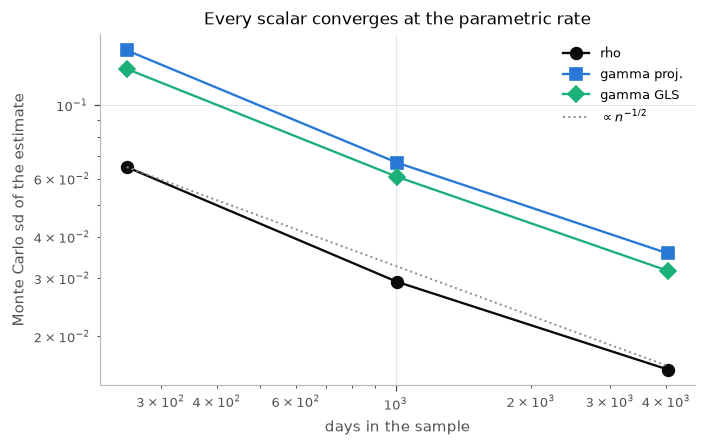

In [10]:
fig, ax = plt.subplots(figsize=(6.4, 3.8))
for name, colour, marker in (("rho", style.INK, "o"), ("gamma proj.", UP, "s"),
                             ("gamma GLS", THIRD, "D")):
    sd = summary.loc[f"{name}: sd"]
    ax.loglog(sd.index, sd.to_numpy(), marker=marker, ms=7, color=colour, lw=1.4, label=name)
ref = summary.loc["rho: sd"].iloc[0] * np.sqrt(sizes[0] / np.array(sizes))
ax.loglog(sizes, ref, color=style.CONTROL, ls=":", lw=1.2, label=r"$\propto n^{-1/2}$")
ax.set_xlabel("days in the sample")
ax.set_ylabel("Monte Carlo sd of the estimate")
ax.set_title("Every scalar converges at the parametric rate")
ax.legend()
plt.show()

252 days is a trading year. Reading the table:

- Every bias is a small fraction of its standard deviation.
- Every interval covers at between 93% and 96.5%, against a nominal 95%.
- Each standard deviation roughly halves when the sample quadruples: the parametric rate, as
  the figure shows.
- The GLS estimator of $\gamma$ has about a fifth less variance than the projection, as the
  Brownian structure of the noise says it should.
- $\gamma$ is the least precise scalar. With one year of data its standard deviation is
  about half the true value, so a single year cannot reliably tell $\gamma = 0.3$ from zero;
  four years can.
- The shape test rejects a true $G(s) = s$ 3% to 5.5% of the time, so it holds its size.
- The test that $\beta \equiv 0$ rejects in 96% of one-year samples and in all of the longer
  ones.

Heavy-tailed jumps change one thing. The estimates stay unbiased, but the robust intervals
for $\gamma$ cover at 91% rather than 95%, because a few very large jumps dominate the
leverage. That is a known small-sample weakness of sandwich standard errors. For heavy-tailed
data, a bootstrap over days is the safer interval.

## 7. Levels or returns: two models of the same day

### 7.1 The difference

The notes put $\beta$ on the *level* of the curve: the jump depends on $\int\beta(u)X_{t-1}(u)
\,\mathrm{d}u$, where $X_{t-1}(u)$ is how far the price had moved since the open by time $u$.
The other natural reading puts the coefficient on the *returns*, the moves made during each
moment of the day: $\int b(v)\,\mathrm{d}X_{t-1}(v)$. The two are linked by integration by
parts. Because $X(0) = 0$,

$$
\int_0^1 \beta(u)\,X(u)\,\mathrm{d}u \;=\; \int_0^1 B(v)\,\mathrm{d}X(v),
\qquad B(v) = \int_v^1 \beta(u)\,\mathrm{d}u .
$$

So the two readings are the *same kind* of model: each says the jump responds to a weighted sum
of the day's returns. They differ in what a simple-looking coefficient means. Take a step at
0.85 in each:

- **Step on the level**, $\beta = \mathbb{1}\{u \ge 0.85\}$, regressor $\int_{0.85}^1 X(u)\,
  \mathrm{d}u$. Its weight on returns is $B(v) = 0.15$ for every return made before 0.85,
  falling linearly to zero over the last stretch. It says: **the jump responds to the whole
  day's move**, with the late returns discounted. The onset is only a kink in that weight.
- **Step on the returns**, $b = \mathbb{1}\{v \ge 0.85\}$, regressor $X(1) - X(0.85)$. It says:
  **only the return made in the last 15% of the session matters**, and everything before is
  irrelevant. The onset is a switch.

**Is there "a random part on the level"? Yes, and that is the whole difference.** The level
at any late time $u$ carries every return made before it. The level-step regressor is
$0.15\,X(0.85)$, which is the morning's entire accumulated move, plus a small late piece, and
the morning accounts for almost all of its variance. If the truth is the return model, that
morning component is pure noise to the jump, and a level regression mostly fits noise. If the
truth is the level model, the morning *is* the signal, and the return model throws most of it
away.

The level is not "more random" in the time-series sense, though. Every day's curve restarts at
zero, so $X_t(u)$ is stationary across days $t$, and regressing on it carries no spurious
regression problem. The difference is purely which returns each regressor adds up.

share of the level regressor's variance that is the morning's move: 0.940
population correlation of the two regressors: 0.182


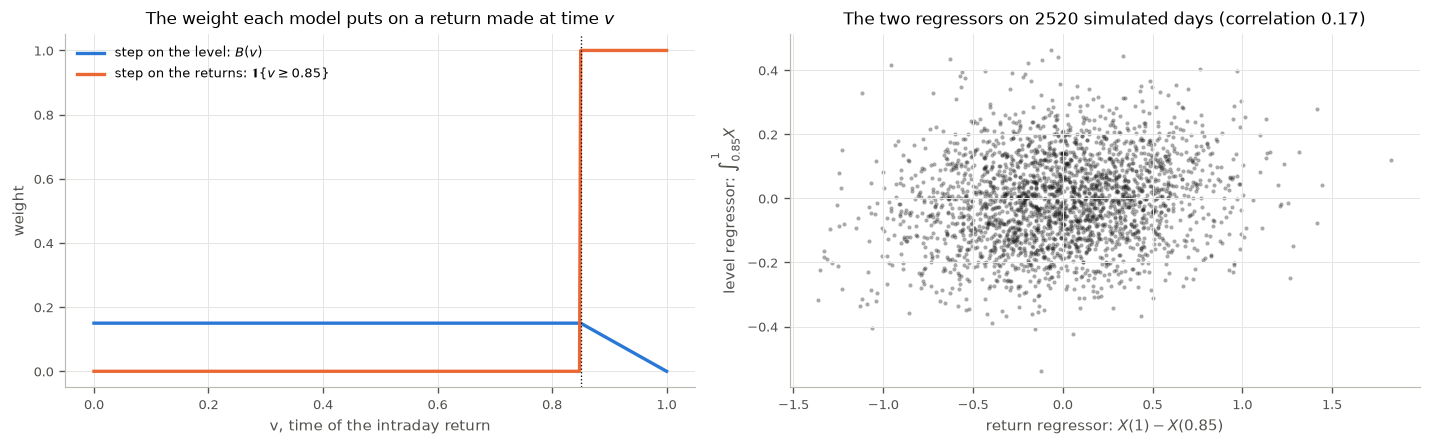

In [11]:
theta = 0.85
start = int(np.argmax(grid >= theta))
c_level = jd.step_functional(grid, theta, "level")
c_return = jd.step_functional(grid, theta, "return")
morning = np.zeros(grid.size)
morning[start] = w[start:].sum()                      # (1 - theta) X(theta), on the grid

cov = mom["cov_X"]
share = (morning @ cov @ c_level) ** 2 / ((morning @ cov @ morning) * (c_level @ cov @ c_level))
corr = (c_level @ cov @ c_return) / np.sqrt((c_level @ cov @ c_level) *
                                            (c_return @ cov @ c_return))
print(f"share of the level regressor's variance that is the morning's move: {share:.3f}")
print(f"population correlation of the two regressors: {corr:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
v = np.linspace(0, 1, 501)
ax[0].plot(v, np.where(v < theta, 1 - theta, 1 - v), color=UP, lw=2,
           label=r"step on the level: $B(v)$")
ax[0].plot(v, (v >= theta).astype(float), color=DOWN, lw=2,
           label=r"step on the returns: $\mathbb{1}\{v \geq 0.85\}$")
ax[0].axvline(theta, color=style.INK, lw=0.8, ls=":")
ax[0].set_title("The weight each model puts on a return made at time $v$")
ax[0].set_xlabel("v, time of the intraday return")
ax[0].set_ylabel("weight")
ax[0].legend()

z_level, z_return = X @ c_level, X @ c_return
ax[1].scatter(z_return, z_level, s=6, color=style.INK, alpha=0.35, lw=0)
ax[1].set_xlabel(r"return regressor: $X(1) - X(0.85)$")
ax[1].set_ylabel(r"level regressor: $\int_{0.85}^1 X$")
ax[1].set_title(f"The two regressors on {X.shape[0]} simulated days "
                f"(correlation {np.corrcoef(z_level, z_return)[0, 1]:.2f})")
plt.tight_layout()
plt.show()

### 7.2 Which one is the jump predictable on?

That depends on which model generated the data, and in a simulation we choose it. Three truths
are built, each with the **same population $R^2$** as the design, so that none has more signal
than another:

- **level**: the design, a step on the level at 0.85;
- **return**: a step on the returns at 0.85, rescaled by `joint_dgp.scale_to_r2`;
- **mixed**: half of each, by variance contribution.

Each is then fitted, *in population*, by a range of models: the regression an infinite sample
would converge to, computed from the solved moments by `joint_dgp.population_fit`, so sampling
error plays no part. The table reports the share of the true $R^2$ each model captures. "Best
step" lets the onset move to wherever fits best. "Day's return" is $X(1)$ alone.

In [12]:
r2_design = mom["r2_jump"]
returns_truth = jd.scale_to_r2(jd.notes_design(beta="return"), r2_design)
ratio_mix = np.sqrt((c_level @ cov @ c_level) / (c_return @ cov @ c_return))
mixed_truth = jd.scale_to_r2(
    model.with_params(beta=model.beta + ratio_mix * jd.notes_beta(grid, "return")), r2_design)
truths = {"level": model, "return": returns_truth, "mixed": mixed_truth}

candidates = grid[1:-1]
rows = {}
for name, truth in truths.items():
    tm = jd.moments(truth)

    def share_of(C, truth=truth, tm=tm):
        return jd.population_fit(truth, C, tm)["r2"] / tm["r2_jump"]

    sw_t = np.sqrt(truth.w)
    _, vecs = np.linalg.eigh(sw_t[:, None] * tm["cov_X"] * sw_t[None, :])
    phi_t = (vecs[:, ::-1] / sw_t[:, None]).T
    best = {on: max(candidates, key=lambda t: share_of(jd.step_functional(grid, t, on)))
            for on in ("level", "return")}
    rows[name] = {
        "jump's lag only": jd.population_fit(truth, None, tm)["r2"] / tm["r2_jump"],
        "step on level at 0.85": share_of(c_level),
        "step on returns at 0.85": share_of(c_return),
        "both steps at 0.85": share_of(np.vstack([c_level, c_return])),
        "best step on level": share_of(jd.step_functional(grid, best["level"], "level")),
        "  ...its onset": best["level"],
        "best step on returns": share_of(jd.step_functional(grid, best["return"], "return")),
        "  ...its onset ": best["return"],
        "day's return X(1)": share_of(np.eye(grid.size)[-1]),
        **{f"components of the level, p = {p}": share_of(phi_t[:p] * truth.w)
           for p in (2, 4, 8, 16)}}
population_table = pd.DataFrame(rows)
print(f"share of the true R^2 ({r2_design:.4f} in every column) captured in population")
print(population_table.round(3).to_string())

share of the true R^2 (0.0805 in every column) captured in population
                                 level  return  mixed
jump's lag only                  0.078   0.097  0.063
step on level at 0.85            1.000   0.124  0.614
step on returns at 0.85          0.107   1.000  0.613
both steps at 0.85               1.000   1.000  1.000
best step on level               1.000   0.224  0.788
  ...its onset                   0.859   0.987  0.987
best step on returns             0.914   1.000  0.802
  ...its onset                   0.013   0.859  0.013
day's return X(1)                0.934   0.244  0.810
components of the level, p = 2   0.970   0.131  0.532
components of the level, p = 4   0.999   0.397  0.732
components of the level, p = 8   1.000   0.842  0.933
components of the level, p = 16  1.000   0.888  0.952


Read the table by column.

- **Level truth.** The level step captures everything, and the return step at 0.85 only a
  tenth of it. A return step is not hopeless, though: moved back to the very start of the
  day, it becomes the day's whole return and captures 91%. That is the integration by parts at
  work. A level step weights every morning return equally, so "the day's return" is a good
  stand-in for it.
- **Return truth.** The level step at 0.85 captures 12%, and even at its best onset only
  22%, about what the day's return manages. A coefficient on the level cannot isolate the
  last stretch's return, because it only sees it through levels that also carry the
  morning. Principal components of the level need eight components to reach 84%, because the
  return step is a pair of point evaluations, $X(1) - X(0.85)$, which smooth eigenfunctions
  approximate slowly.
- **Mixed truth.** Each step alone captures about 61%, and both together capture all of it.
- **The first row differs across columns** although $\rho$ is the same in all three. That is
  section 1's point 2: $\beta$ feeds the gap-fill of yesterday's jump back into tonight's, so
  how much the jump's own lag explains depends on $\beta$.

So the jump is predictable on whichever regressor the truth uses, and the costs are
asymmetric. If the truth is on levels, a returns model spanning the whole day loses little.
If the truth is on returns, a levels model loses most of the signal. Which one holds is an
empirical question, and it can be put to the data directly. `joint_est.nesting_test`
regresses the jump on *both* regressors at the hypothesised onset of 0.85. The t-test on each
asks whether that model adds anything to the other. With one non-shared regressor on each side,
that t-test is exactly the J test for non-nested models [[26]](../docs/references.md#ref-davidson-mackinnon-1981).

In [13]:
nesting = {}
for name, truth in truths.items():
    for n in (252, 1260):
        p_level, p_return = [], []
        for r in range(200):
            s = jd.simulate(truth, n, rng=40_000 + r)
            test = est.nesting_test(s["J"], s["X"], grid, theta)
            p_level.append(test["p_value"]["level"])
            p_return.append(test["p_value"]["return"])
        nesting[(name, n)] = {"level term significant": np.mean(np.array(p_level) < 0.05),
                              "return term significant": np.mean(np.array(p_return) < 0.05)}
nesting_table = pd.DataFrame(nesting).T
nesting_table.index.names = ["truth", "days"]
print("rejection rates at 5% over 200 replications, onset 0.85 taken as the hypothesis")
print(nesting_table.round(3).to_string())

rejection rates at 5% over 200 replications, onset 0.85 taken as the hypothesis
             level term significant  return term significant
truth  days                                                 
level  252                    1.000                    0.035
       1260                   1.000                    0.060
return 252                    0.050                    0.990
       1260                   0.045                    1.000
mixed  252                    0.815                    0.860
       1260                   1.000                    1.000


The test names the model.

- **Level truth**: the level term is significant in every sample, and the return term only at
  about its nominal 5%.
- **Return truth**: the reverse.
- **Mixed truth**: both terms are significant, in more than four of five one-year samples
  and in every five-year one.

One year of data is enough, *given* the onset. The onset itself is the next question:
`joint_est.onset_profile` profiles the residual sum of squares over it, under the step form
the notes write down, for each truth.

first grid point at or after 0.85: 0.8590; 100 replications per row
                   exactly right  within 0.03  median    IQR
level, n = 504              0.08         0.24   0.865  0.131
level, n = 2520             0.14         0.54   0.859  0.051
level, n = 10080            0.19         0.84   0.859  0.038
return, n = 504             0.59         0.85   0.859  0.013
return, n = 2520            0.96         1.00   0.859  0.000
return, n = 10080           1.00         1.00   0.859  0.000


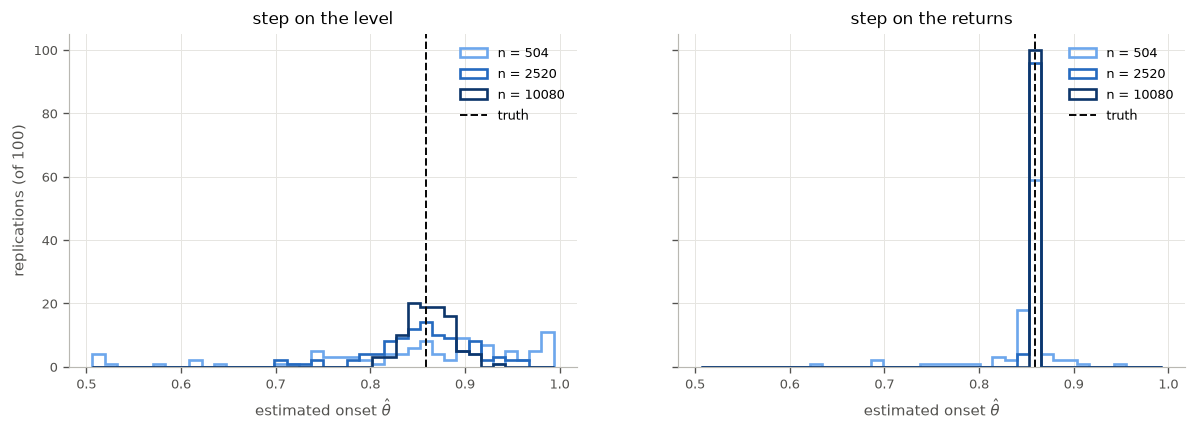

In [14]:
onsets = grid[(grid > 0.5) & (grid < 0.99)]
onset = grid[start]
found = {}
for label, design in (("level", model), ("return", returns_truth)):
    for n in (504, 2520, 10080):
        hats = []
        for r in range(100):
            s = jd.simulate(design, n, rng=50_000 + r)
            hats.append(est.onset_profile(s["J"], s["X"], grid, onsets, on=label)["theta_hat"])
        found[(label, n)] = np.array(hats)

onset_table = pd.DataFrame({
    f"{label}, n = {n}": {"exactly right": np.mean(h == onset),
                          "within 0.03": np.mean(np.abs(h - onset) < 0.03),
                          "median": np.median(h),
                          "IQR": np.subtract(*np.percentile(h, [75, 25]))}
    for (label, n), h in found.items()}).T
print(f"first grid point at or after 0.85: {onset:.4f}; 100 replications per row")
print(onset_table.round(3).to_string())

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6), sharey=True)
edges = np.concatenate([onsets - 0.5 / 78, [onsets[-1] + 0.5 / 78]])
for a, label in zip(ax, ("level", "return")):
    for n, colour in zip((504, 2520, 10080), style.ordinal(3, lightest=4)):
        a.hist(found[(label, n)], bins=edges, histtype="step", lw=1.6, color=colour,
               label=f"n = {n}")
    a.axvline(onset, color=style.INK, lw=1.2, ls="--", label="truth")
    a.set_xlabel(r"estimated onset $\hat\theta$")
    a.set_title(f"step on the {label}" + ("" if label == "level" else "s"))
    a.legend()
ax[0].set_ylabel("replications (of 100)")
plt.show()

In [15]:
def partial_out_lag(J, X):
    # Frisch-Waugh: jump and lagged curves, each with (1, J_{t-1}) projected out.
    C = np.column_stack([np.ones(J.size - 1), J[:-1]])
    residual = lambda Z: Z - C @ np.linalg.lstsq(C, Z, rcond=None)[0]
    return residual(X[:-1]), residual(J[1:])


lambdas = np.linspace(0.0, 1.0, 21)[1:]
hh_hat = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for r in range(10):
        s = jd.simulate(model, 2520, rng=60_000 + r)
        Xr, yr = partial_out_lag(s["J"], s["X"])
        hh_hat.append(HH.fit_mirror(Xr, yr, grid, lambdas)["u_hat"])
hh_hat = np.array(hh_hat)
print(f"Hall & Hooker method B, step on the level, n = 2520, 10 replications: "
      f"{np.round(hh_hat, 3)}")
print(f"median {np.median(hh_hat):.3f}; within 0.03 of the truth: "
      f"{np.mean(np.abs(hh_hat - 0.85) < 0.03):.1f}")

Hall & Hooker method B, step on the level, n = 2520, 10 replications: [0.872 0.846 0.808 0.885 0.833 0.936 0.846 0.859 0.808 0.782]
median 0.846; within 0.03 of the truth: 0.5


At equal signal, the onset is sharply identified on returns and only loosely on levels.

- **On returns**, the onset lands on exactly the right grid point in 96% of ten-year samples
  and in all forty-year ones, and within 0.03 of it in every ten-year sample.
- **On levels**, it lands exactly right in at most a fifth of samples at any size. It is
  within 0.03 in about half of ten-year samples and in 84% at forty years.
- **Hall & Hooker's method B**, which does not assume a step, is no sharper on levels. Half
  its ten estimates land within 0.03; the rest scatter between 0.782 and 0.936.

This is not a weakness of either estimator. Neighbouring values of a cumulative curve are
almost collinear, so moving a level onset by a few grid points barely changes the regressor
$\int_\theta^1 X$, whereas moving the start of a return window adds or removes an independent
increment. If the hypothesis is about *when* in the day the information arrives, the returns
form is the one in which "when" can be estimated.

## 8. The sign of $\Psi$: continuation or reversal

$\Psi(s, r)$ says how yesterday's curve moves today's. Leaving the rest of the curve equation
aside, today's expected curve contains $\int\Psi(s,r)X_{t-1}(r)\,\mathrm{d}r$.

- If $\Psi \ge 0$ everywhere, as $s\,e^{-(s-r)^2/c}$ is, then after a day that rose, every part
  of today is pushed *up*. Good days are followed by good days: **continuation**, or momentum.
- Multiply the kernel by $-1$ and the same day pushes today *down*: **reversal**, or mean
  reversion.

Which of the two holds for a given market and period is an empirical question, and day-to-day
reversal is at least as commonly reported as continuation. The notes' kernel can produce only
the first, so the design needs a sign if it is to cover both.

`notes_design(psi_scale=-1)` is the reversal design, with everything else unchanged. The figure
uses `joint_dgp.forecast`, the model's conditional expectation, to show what each design
expects of today after a day that rose steadily by 1%.

continuation  radius 0.217, lag-1 autocorrelation of the day's return X(1) +0.184, expected close after the up day +0.153 against -0.046
reversal      radius 0.326, lag-1 autocorrelation of the day's return X(1) -0.262, expected close after the up day -0.308 against -0.029


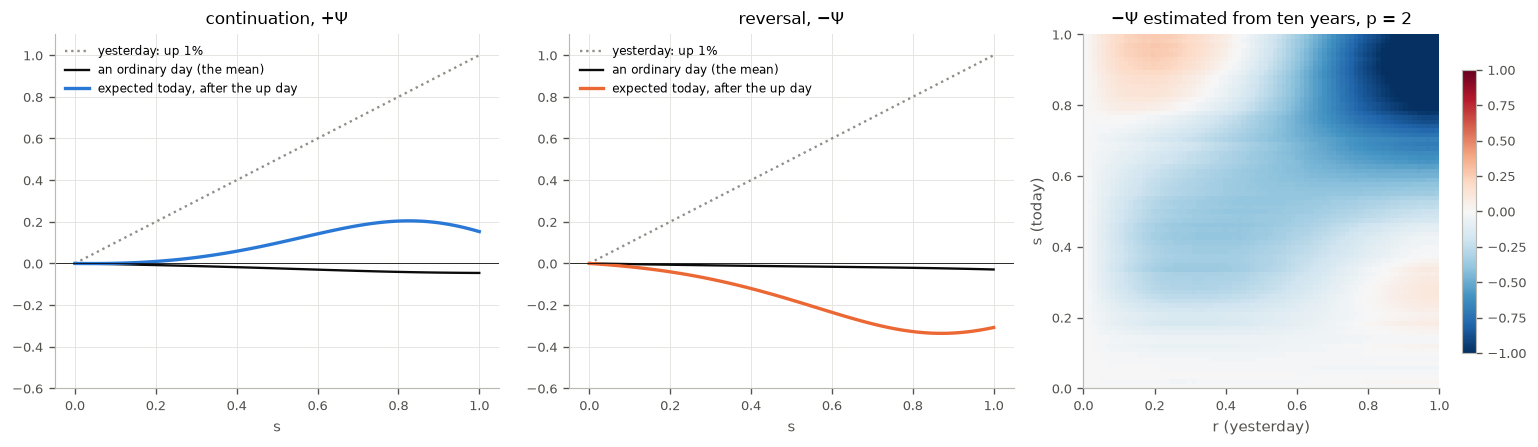

reversal kernel: correlation of estimate with truth 0.930, Hilbert-Schmidt error 0.104 against a kernel norm of 0.333


In [16]:
reversal = jd.notes_design(psi_scale=-1.0)
up_day = 1.0 * grid
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
for a, label, design, colour in ((ax[0], "continuation, $+\\Psi$", model, UP),
                                 (ax[1], "reversal, $-\\Psi$", reversal, DOWN)):
    dm = jd.moments(design)
    EJ_up, EX_up = jd.forecast(design, dm["mean_J"], up_day)
    a.plot(grid, up_day, color=style.CONTROL, lw=1.4, ls=":", label="yesterday: up 1%")
    a.plot(grid, dm["mean_X"], color=style.INK, lw=1.4, label="an ordinary day (the mean)")
    a.plot(grid, EX_up, color=colour, lw=2, label="expected today, after the up day")
    a.axhline(0, color=style.INK, lw=0.5)
    a.set_title(label)
    a.set_xlabel("s")
    a.set_ylim(-0.6, 1.1)
    a.legend(fontsize=7, loc="upper left")
    acf = dm["lag1"][-1, -1] / dm["cov_X"][-1, -1]
    print(f"{label.split(',')[0]:<13} radius {jd.stationarity(design)['radius']:.3f}, "
          f"lag-1 autocorrelation of the day's return X(1) {acf:+.3f}, "
          f"expected close after the up day {EX_up[-1]:+.3f} against {dm['mean_X'][-1]:+.3f}")

sim_r = jd.simulate(reversal, 2520, rng=2)
K = est.fit_curve_equation(sim_r["J"], sim_r["X"], grid, 2)["kernel"]
image = ax[2].imshow(K, origin="lower", extent=[0, 1, 0, 1], cmap="RdBu_r", vmin=-1, vmax=1,
                     aspect="auto")
ax[2].grid(False)
ax[2].set_title(r"$-\Psi$ estimated from ten years, p = 2")
ax[2].set_xlabel("r (yesterday)")
ax[2].set_ylabel("s (today)")
fig.colorbar(image, ax=ax[2], shrink=0.8)
plt.tight_layout()
plt.show()
print(f"reversal kernel: correlation of estimate with truth "
      f"{np.corrcoef(K.ravel(), reversal.kernel.ravel())[0, 1]:.3f}, Hilbert-Schmidt error "
      f"{est.hs_distance(K, reversal.kernel, grid):.3f} against a kernel norm of "
      f"{est.hs_distance(reversal.kernel, 0 * K, grid):.3f}")

Both signs give a stationary model, and the estimator recovers either, so keeping the choice
open costs nothing. The practical recommendation is to write the kernel as $\kappa\,s\,
e^{-(s-r)^2/c}$, with the scale $\kappa$ free in sign, and let the data choose. That is
`psi_scale` here.

## 9. The shape of $G$, and a random $\gamma_t$

### 9.1 What $G$ means

After an overnight jump $J_t$, the curve equation subtracts $\gamma_t G(s) J_t$: by time $s$,
the session has given back a fraction $\gamma_t G(s)$ of the gap. $G$ runs from $G(0) = 0$ at
the open to $G(1) = 1$ at the close, so $\gamma_t$ is the share given back by the close, and $G$
is **when during the day it happens**.

- $G(s) = s$ (the notes): the gap is given back at a constant rate, a little every minute.
- **Front-loaded**, $G(s) \propto 1 - e^{-s/\tau}$: most of it goes in the first $\tau$ of the
  session, the way a gap is often said to be "filled in the first hour", and the price then
  wanders as usual.

The two end at the same place, so they agree on $\gamma$ and on the close, and differ about every
moment in between. The figure draws the expected price path after a 1% gap up under each, with
yesterday's close at zero.

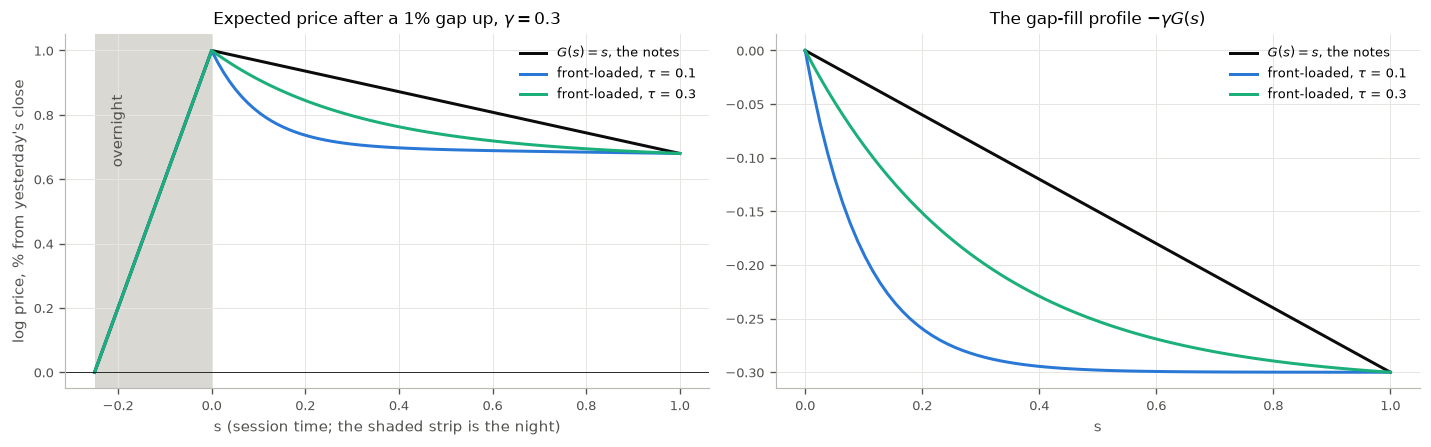

In [17]:
profiles = (("$G(s) = s$, the notes", model.G, style.INK),
            (r"front-loaded, $\tau$ = 0.1", jd.gapfill_profile(grid, "front", 0.1), UP),
            (r"front-loaded, $\tau$ = 0.3", jd.gapfill_profile(grid, "front", 0.3), THIRD))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
x_day = np.concatenate([[-0.25], grid])
for label, G, colour in profiles:
    path = 1.0 + model.mu - model.gamma_mean * G * 1.0
    ax[0].plot(x_day, np.concatenate([[0.0], path]), color=colour, lw=1.8, label=label)
    ax[1].plot(grid, -model.gamma_mean * G, color=colour, lw=1.8, label=label)
ax[0].axvspan(-0.25, 0, color=style.BAND, lw=0)
ax[0].text(-0.2, 0.75, "overnight", ha="center", va="center", rotation=90, color=style.MUTED)
ax[0].axhline(0, color=style.INK, lw=0.5)
ax[0].set_title(r"Expected price after a 1% gap up, $\gamma = 0.3$")
ax[0].set_xlabel("s (session time; the shaded strip is the night)")
ax[0].set_ylabel("log price, % from yesterday's close")
ax[0].legend()
ax[1].set_title(r"The gap-fill profile $-\gamma G(s)$")
ax[1].set_xlabel("s")
ax[1].legend()
plt.tight_layout()
plt.show()

### 9.2 Testing $G(s) = s$

The curve equation estimates the whole profile $\hat b(s)$ without assuming any $G$, so whether
$G(s) = s$ is a question that can be put to the data. `joint_est.shape_test` asks whether
$\hat b(s)$ is a multiple of $s$. Its statistic is the $L^2$ norm of the part of $\hat b$
orthogonal to $s$, whose null distribution is a weighted sum of $\chi^2_1$, as in Shen &
Faraway's functional $F$ test [[77]](../docs/references.md#ref-shen-faraway-2004). The p-value is the exact tail of that law, by Imhof's
inversion [[48]](../docs/references.md#ref-imhof-1961). Its size under the null was measured in section 6; here is its power, with each
front-loaded design otherwise identical to the main one.

In [18]:
power = {}
for tau in (0.1, 0.3):
    design = jd.notes_design(gap="front", tau=tau)
    for n in (252, 504, 1008):
        p_values = []
        for r in range(100):
            s = jd.simulate(design, n, rng=80_000 + r)
            p_values.append(est.shape_test(est.fit_curve_equation(s["J"], s["X"], grid,
                                                                  4))["p_value"])
        power[(tau, n)] = np.mean(np.array(p_values) < 0.05)
size = summary.loc["shape test: rejects at 5%"]
print("rejection rate at 5% (the null from section 6's 200 replications, the rest from 100)")
print("  G(s) = s, the null:        " + "  ".join(f"n={n}: {v:.3f}" for n, v in size.items()))
for tau in (0.1, 0.3):
    print(f"  front-loaded, tau = {tau}:  " + "  ".join(f"n={n}: {power[(tau, n)]:.2f}"
                                                        for n in (252, 504, 1008)))

rejection rate at 5% (the null from section 6's 200 replications, the rest from 100)
  G(s) = s, the null:        n=252: 0.030  n=1008: 0.055  n=4032: 0.055
  front-loaded, tau = 0.1:  n=252: 0.91  n=504: 1.00  n=1008: 1.00
  front-loaded, tau = 0.3:  n=252: 0.49  n=504: 0.79  n=1008: 0.96


The test holds its size and has real power.

- Against a gap that closes in the first tenth of the session, it rejects $G(s) = s$ in 91% of
  one-year samples and in every longer one.
- Against the gentler $\tau = 0.3$, it rejects in about half of one-year samples, four in five
  at two years, and nearly all at four.

Where it rejects, $\hat b(s)$ is itself the estimate of the profile, so nothing about $G$ has
to be assumed in the first place.

### 9.3 A random $\gamma_t$

With $\gamma_t \sim U(0, 1)$, some days give back almost none of the gap and some almost all,
half on average. Both estimators of $\gamma$ still estimate the mean. $\gamma_t$ is independent
of $J_t$, so the extra term $(\gamma_t - \bar\gamma)G(s)J_t$ is a mean-zero error that is
heteroskedastic in $J_t$, and the robust standard errors absorb it. That same
heteroskedasticity identifies $\operatorname{Var}\gamma_t$: `joint_est.gamma_variance`
regresses squared residuals on $G(s)^2J_t^2$. The question is how much data that takes.

In [19]:
model_u = jd.notes_design(gamma=0.5, gamma_dist="uniform")
check_u = jd.stationarity(model_u)
print(f"gamma_t ~ U(0, 1): radius {check_u['radius']:.4f}, mean-square radius "
      f"{check_u['ms_radius']:.4f} (a fixed gamma = 0.5 would give "
      f"{check_u['radius'] ** 2:.4f})")

rows = []
for n in (1008, 4032, 16128):
    for r in range(60):
        s = jd.simulate(model_u, n, rng=70_000 + r)
        cf = est.fit_curve_equation(s["J"], s["X"], grid, 4)
        gv = est.gamma_variance(cf)
        rows.append({"n": n, "gamma_gls": cf["gamma_gls"], "var": gv["var"],
                     "se_var": gv["se"], "t": gv["t"]})
random_gamma = pd.DataFrame(rows).groupby("n").agg(
    gamma_mean=("gamma_gls", "mean"), gamma_sd=("gamma_gls", "std"),
    var_mean=("var", "mean"), var_sd=("var", "std"), mean_se=("se_var", "mean"),
    detected=("t", lambda t: np.mean(t > 1.645)))
print(f"\ntruth: mean 0.5, variance {1 / 12:.4f}; 60 replications per row")
print(random_gamma.round(4).to_string())

gamma_t ~ U(0, 1): radius 0.1902, mean-square radius 0.0409 (a fixed gamma = 0.5 would give 0.0362)



truth: mean 0.5, variance 0.0833; 60 replications per row
       gamma_mean  gamma_sd  var_mean  var_sd  mean_se  detected
n                                                               
1008       0.5049    0.0648    0.0860  0.1531   0.1266    0.1500
4032       0.4942    0.0312    0.0861  0.0660   0.0671    0.3667
16128      0.4998    0.0163    0.0836  0.0330   0.0338    0.8167


The mean of $\gamma_t$ comes back at every size; its variance comes back unbiased, but slowly.
The variance is identified only through the fourth moment of the jump, and the random part of
the gap-fill is small beside the curve noise. A one-sided 5% test detects it in 15% of
four-year samples, in 37% at sixteen years, and in 82% only at sixty-four. This is partly the
design. With jumps larger relative to the session noise, identification is much faster, which
is the design `tests/test_joint.py` checks the estimator on.

On real data there is also a confound that the simulation does not have. A large overnight
move tends to be followed by a volatile session, which raises the curve noise along with
$J_t^2$, exactly as a random $\gamma_t$ would. A significant $\operatorname{Var}\gamma_t$ would
not, on its own, tell the two apart.

## 10. The smooth $\beta$

The notes' second coefficient function, $\{e^{u-0.85} - 1\}\mathbb{1}\{u \ge 0.85\}$, is
continuous at the onset, but much smaller. At the same amplitude it is a different experiment,
not a harder version of the same one.

In [20]:
smooth = jd.notes_design(beta="smooth")
r2_smooth = jd.moments(smooth)["r2_jump"]
r2_floor = jd.population_fit(smooth, None)["r2"]
print(f"population R^2: indicator beta {r2_design:.4f}, smooth beta {r2_smooth:.4f}, "
      f"the jump's lag alone {r2_floor:.4f}")
rejections = []
for r in range(100):
    s = jd.simulate(smooth, 2520, rng=90_000 + r)
    rejections.append(est.fit_jump_equation(s["J"], s["X"], grid, 4)["fit"].wald(
        "d", hac=False)[2])
print(f"joint test of beta = 0 at n = 2520 rejects in "
      f"{np.mean(np.array(rejections) < 0.05):.2f} of 100 replications (5% level)")
print(f"\nnotebook ran in {time.perf_counter() - CLOCK:.0f} s")

population R^2: indicator beta 0.0805, smooth beta 0.0099, the jump's lag alone 0.0093


joint test of beta = 0 at n = 2520 rejects in 0.15 of 100 replications (5% level)

notebook ran in 134 s


At the notes' amplitude the smooth coefficient function adds almost nothing. The population
$R^2$ is 0.0099 against 0.0093 for the jump's lag alone, and ten years of data detect it in
15% of samples. To study its shape, give it a target $R^2$ through `joint_dgp.scale_to_r2`, so
that the experiment says which $R^2$ it is about.

## 11. What to take from this

The model in the notes is sound once it is read as one system rather than two equations. It is
stationary, its moments can be solved for exactly, and every scalar in it is recoverable at the
rate a parametric model should be. Estimating it one equation at a time loses nothing, because
the system is recursive with independent errors.

Three modelling choices decide what it *means*, and each now has a simulation that shows what
is at stake and a test that settles it from data. `docs/jump-model-choices.md` sets them out
without the code.

1. **Levels or returns for $\beta$.** A step on the level and a step on the returns are
   different hypotheses: "the jump responds to the day's move" against "the jump responds to
   the late move". The nesting test tells them apart from a year of data, and only the returns
   form has an onset that can be found sharply. If the claim is about the late session, write
   it on returns, or fit both and let the test decide.
2. **A sign for $\Psi$.** Keep the kernel's scale free in sign, so that both continuation and
   reversal are allowed.
3. **The shape of $G$.** Estimate $\hat b(s)$ unrestricted first, then test $G(s) = s$ against
   it. Assume a parametric $G$ only if the test does not reject.

Before the method meets real data:

- The curves must be built with `fdaSP.intraday.session_curves(..., anchor="open")`, or the
  first bar's return is in neither the curve nor the jump and the identities fail.
- Under heavy tails, intervals should come from a bootstrap over days that redoes the
  decomposition. That also covers the generated-regressor problem of the principal component
  scores [[64]](../docs/references.md#ref-pagan-1984).
- $\operatorname{Var}\gamma_t$ should be read only after modelling how the session's volatility
  depends on the size of the jump.